**Daily Weather Time Series Data - Delhi, India**

https://www.kaggle.com/datasets/yug201/daily-climate-time-series-data-delhi-india?select=kaggel_weather_2013_to_2024.csv

**Тема:** Прогнозування часових рядів на основі кліматичних даних

**Мета роботи:**
Навчитися виконувати аналіз часових рядів, проводити дослідницький аналіз даних (EDA), визначати автокореляційні залежності, будувати моделі прогнозування та оцінювати їхню точність.

**Вихідні дані**

Для виконання роботи використовується датасет Daily Climate Time Series Data (Delhi, India) з платформи Kaggle, який містить щоденні кліматичні показники (температура, вологість, опади тощо) за кілька років.


1. Завантажити датасет з Kaggle.

2. Імпортувати дані у середовище Python (Jupyter Notebook або Google Colab).

3. Ознайомитися зі структурою датасету (head(), info(), describe()).

4. Попередня обробка даних

-Перетворити колонку з датою у формат datetime.

-Відсортувати дані за датою.

-Встановити дату як індекс часового ряду.

-Перевірити наявність пропущених значень та за необхідності обробити їх.

5. Дослідницький аналіз даних (EDA)

-Побудувати графік зміни температури у часі.

-Побудувати ковзне середнє значення температури.

-Побудувати гістограму розподілу температури.

-Побудувати boxplot для виявлення можливих викидів.

-Аналіз автокореляції

Побудувати графік автокореляційної функції (ACF).

Побудувати графік часткової автокореляції (PACF).

-Проаналізувати залежність значень часового ряду від попередніх періодів.

6.Підготовка даних для моделювання

-Розділити дані на тренувальну та тестову вибірки (наприклад, 80% / 20%).

7. Побудувати щонайменше три моделі прогнозування:

-ARIMA (класична статистична модель);

-Prophet (модель прогнозування часових рядів від Meta);

-LSTM (нейронна мережа для послідовних даних).

8. Оцінка моделей
Для кожної моделі обчислити метрики:

-MAE (Mean Absolute Error)

-RMSE (Root Mean Squared Error)

-MAPE (Mean Absolute Percentage Error)

8.Візуалізація результатів

-Побудувати графіки прогнозованих та фактичних значень.

-Побудувати порівняльний графік прогнозів усіх моделей.

-Порівняння моделей

-Створити таблицю з метриками точності.

9.Визначити модель, яка показала найкращий результат.

In [1]:
# Імпортуйте необхідні бібліотеки

# Імпорт основних бібліотек для роботи з даними та візуалізації
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Бібліотеки для завантаження даних та аналізу часових рядів
import kagglehub
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA
from prophet import Prophet

# Бібліотеки для нормування та оцінки якості моделей
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error

# Бібліотеки для побудови нейронної мережі LSTM
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout

# Налаштування стилю відображення графіків
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (14, 6)


In [2]:
# Завантажте датасет з Kaggle

# Завантаження останньої версії датасету з Kaggle
path = kagglehub.dataset_download("yug201/daily-climate-time-series-data-delhi-india")

print("Шлях до завантажених файлів:", path)

# Перевірка списку завантажених файлів
files = os.listdir(path)
print("Файли у директорії:", files)


Using Colab cache for faster access to the 'daily-climate-time-series-data-delhi-india' dataset.
Шлях до завантажених файлів: /kaggle/input/daily-climate-time-series-data-delhi-india
Файли у директорії: ['kaggel_weather_2013_to_2024.csv']


In [3]:
# Зчитайте датасет у DataFrame та перегляньте дані

import os
import pandas as pd
import kagglehub

# 1. Завантажуємо датасет з Kaggle
path = kagglehub.dataset_download("yug201/daily-climate-time-series-data-delhi-india")
print("Шлях до директорії:", path)

# 2. Знаходимо всі CSV-файли у директорії
csv_files = []
for root, dirs, files in os.walk(path):
    for file in files:
        if file.endswith(".csv"):
            csv_files.append(os.path.join(root, file))

print("Знайдені CSV-файли:", csv_files)

# 3. Зчитуємо перший знайдений CSV-файл
df_raw = pd.read_csv(csv_files[0])

# 4. Перегляд структури та вмісту
print("\n--- Перші 5 рядків (head) ---")
print(df_raw.head())

print("\n--- Інформація про типи даних (info) ---")
df_raw.info()

print("\n--- Статистичний опис (describe) ---")
print(df_raw.describe())

Using Colab cache for faster access to the 'daily-climate-time-series-data-delhi-india' dataset.
Шлях до директорії: /kaggle/input/daily-climate-time-series-data-delhi-india
Знайдені CSV-файли: ['/kaggle/input/daily-climate-time-series-data-delhi-india/kaggel_weather_2013_to_2024.csv']

--- Перші 5 рядків (head) ---
   Unnamed: 0       DATE  tempmax  tempmin  temp  feelslikemax  feelslikemin  \
0           0  4/14/2013     37.7     23.1  28.7          35.4          23.1   
1           1  4/15/2013     37.5     21.1  28.6          35.3          21.1   
2           2  4/16/2013     40.1     21.9  31.7          37.5          21.9   
3           3  4/17/2013     36.4     21.0  29.9          34.0          21.0   
4           4  4/18/2013     37.5     21.7  30.6          35.2          21.7   

   feelslike  humidity  precip  ...  year-2000  weekofyear  tempmax_humidity  \
0       28.1      39.7     2.0  ...         13          15           1496.69   
1       28.0      41.7     0.0  ...      

Підготовка даних

In [4]:
# Виконайте попередню обробку даних:
# Копіюємо вихідний DataFrame
df = df_raw.copy()

# 1. Приведення колонки з датою до формату datetime
# (Враховуємо різні варіанти назви колонки: 'date' або 'DATE')
date_col = [col for col in df.columns if col.lower() == 'date'][0]
df[date_col] = pd.to_datetime(df[date_col])

# 2. Сортування даних за датою
df = df.sort_values(by=date_col)

# 3. Видалення зайвих колонок (залишаємо лише необхідні кліматичні показники, наприклад, 'meantemp')
columns_to_drop = [col for col in ['Unnamed: 0', 'index'] if col in df.columns]
if columns_to_drop:
    df = df.drop(columns=columns_to_drop)

# 4. Встановлення колонки з датою як індексу
df.set_index(date_col, inplace=True)

# 5. Перевірка та обробка пропущених значень (за наявності)
df = df.interpolate(method='linear')

# Перегляд результату
print("--- Перші 5 рядків після обробки ---")
print(df.head())

print("\n--- Інформація про оновлений DataFrame ---")
df.info()


--- Перші 5 рядків після обробки ---
            tempmax  tempmin  temp  feelslikemax  feelslikemin  feelslike  \
DATE                                                                        
2013-04-14     37.7     23.1  28.7          35.4          23.1       28.1   
2013-04-15     37.5     21.1  28.6          35.3          21.1       28.0   
2013-04-16     40.1     21.9  31.7          37.5          21.9       30.4   
2013-04-17     36.4     21.0  29.9          34.0          21.0       28.5   
2013-04-18     37.5     21.7  30.6          35.2          21.7       29.2   

            humidity  precip  precipprob  precipcover  ...  year-2000  \
DATE                                                   ...              
2013-04-14      39.7     2.0         100         4.17  ...         13   
2013-04-15      41.7     0.0           0         0.00  ...         13   
2013-04-16      30.7     0.0           0         0.00  ...         13   
2013-04-17      27.4     0.0           0         0.00  ...

/tmp/ipykernel_652/4143340542.py:23: FutureWarning: DataFrame.interpolate with object dtype is deprecated and will raise in a future version. Call obj.infer_objects(copy=False) before interpolating instead.
  df = df.interpolate(method='linear')


In [5]:
# Перегляньте інформацію про структуру датасету

# 1. Загальна інформація про DataFrame (кількість рядків, колонок, типи даних та пам'ять)
print("=== Загальна інформація про датасет (info) ===")
df.info()

# 2. Розмірність датасету (кількість рядків та колонок)
print("\n=== Розмірність датасету (shape) ===")
print(f"Рядків: {df.shape[0]}, Колонок: {df.shape[1]}")

# 3. Перевірка наявності пропущених значень (NaN)
print("\n=== Кількість пропущених значень ===")
print(df.isnull().sum())

# 4. Основні статистичні показники (середнє, стандартне відхилення, min, max, квантилі)
print("\n=== Описова статистика (describe) ===")
print(df.describe().T)


=== Загальна інформація про датасет (info) ===
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 3557 entries, 2013-04-14 to 2024-11-30
Data columns (total 27 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   tempmax                3557 non-null   float64
 1   tempmin                3557 non-null   float64
 2   temp                   3557 non-null   float64
 3   feelslikemax           3557 non-null   float64
 4   feelslikemin           3557 non-null   float64
 5   feelslike              3557 non-null   float64
 6   humidity               3557 non-null   float64
 7   precip                 3557 non-null   float64
 8   precipprob             3557 non-null   int64  
 9   precipcover            3557 non-null   float64
 10  windspeed              3557 non-null   float64
 11  sealevelpressure       3557 non-null   float64
 12  conditions             3557 non-null   object 
 13  Year                   3557 non-null   int6

In [6]:
# Перевірте наявність пропущених значень

# 1. Підрахунок кількості пропущених значень у кожній колонці
missing_values = df.isnull().sum()
missing_percentage = (df.isnull().sum() / len(df)) * 100

# Формування підсумкової таблиці пропусків
missing_info = pd.DataFrame({
    'Кількість пропусків': missing_values,
    'Відсоток пропусків (%)': missing_percentage.round(2)
})

print("=== Аналіз пропущених значень ===")
print(missing_info)

# 2. Якщо пропуски є — заповнюємо їх методом лінійної інтерполяції (для часових рядів)
if df.isnull().sum().sum() > 0:
    print("\nВиявлено пропущені значення! Виконується інтерполяція...")
    df = df.interpolate(method='linear')
    # Для можливих крайніх значень застосовуємо ffill/bfill
    df = df.bfill().ffill()
    print("Пропущені значення успішно заповнені.")
else:
    print("\nПропущених значень не виявлено (датасет повний).")


=== Аналіз пропущених значень ===
                       Кількість пропусків  Відсоток пропусків (%)
tempmax                                  0                     0.0
tempmin                                  0                     0.0
temp                                     0                     0.0
feelslikemax                             0                     0.0
feelslikemin                             0                     0.0
feelslike                                0                     0.0
humidity                                 0                     0.0
precip                                   0                     0.0
precipprob                               0                     0.0
precipcover                              0                     0.0
windspeed                                0                     0.0
sealevelpressure                         0                     0.0
conditions                               0                     0.0
Year                        

Графік температури

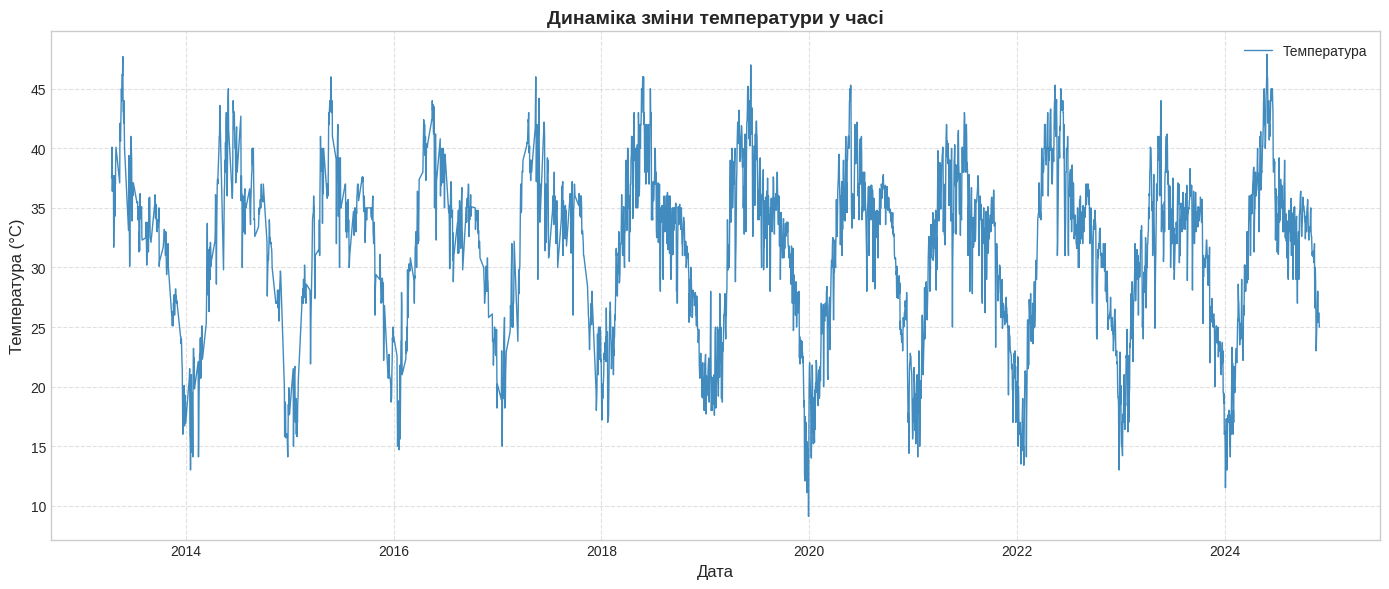

In [7]:
# Побудуйте графік зміни температури у часі
import matplotlib.pyplot as plt

# Автоматично визначаємо колонку з температурою (наприклад, 'meantemp' або 'temperature')
temp_col = [col for col in df.columns if 'temp' in col.lower()][0]

# Побудова графіка
plt.figure(figsize=(14, 6))
plt.plot(df.index, df[temp_col], color='tab:blue', linewidth=1, alpha=0.85, label='Температура')

plt.title('Динаміка зміни температури у часі', fontsize=14, fontweight='bold')
plt.xlabel('Дата', fontsize=12)
plt.ylabel('Температура (°C)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()


Ковзне середнє

In [ ]:
# Обчисліть та візуалізуйте ковзне середнє температури


Розподіл температури

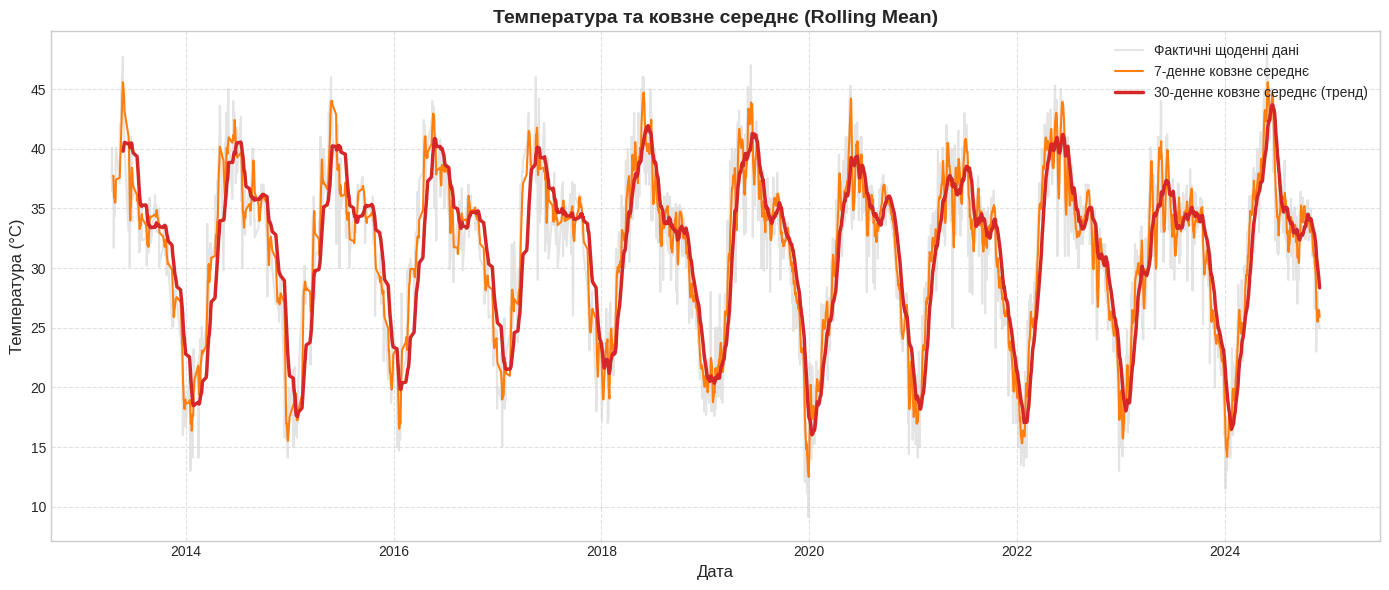

In [8]:
# Побудуйте гістограму розподілу температури
import matplotlib.pyplot as plt

# Автоматичне визначення колонки з температурою
temp_col = [col for col in df.columns if 'temp' in col.lower()][0]

# Обчислення ковзного середнього за 7 днів (тижневе) та 30 днів (місячне)
df['rolling_7'] = df[temp_col].rolling(window=7).mean()
df['rolling_30'] = df[temp_col].rolling(window=30).mean()

# Побудова графіка
plt.figure(figsize=(14, 6))

# Фактичні дані (напівпрозорі на фоні)
plt.plot(df.index, df[temp_col], color='lightgray', alpha=0.6, label='Фактичні щоденні дані')

# Ковзне середнє
plt.plot(df.index, df['rolling_7'], color='tab:orange', linewidth=1.5, label='7-денне ковзне середнє')
plt.plot(df.index, df['rolling_30'], color='tab:red', linewidth=2.5, label='30-денне ковзне середнє (тренд)')

plt.title('Температура та ковзне середнє (Rolling Mean)', fontsize=14, fontweight='bold')
plt.xlabel('Дата', fontsize=12)
plt.ylabel('Температура (°C)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()


/tmp/ipykernel_652/2236312481.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='month', y=temp_col, data=df_monthly, ax=axes[1], palette='coolwarm')


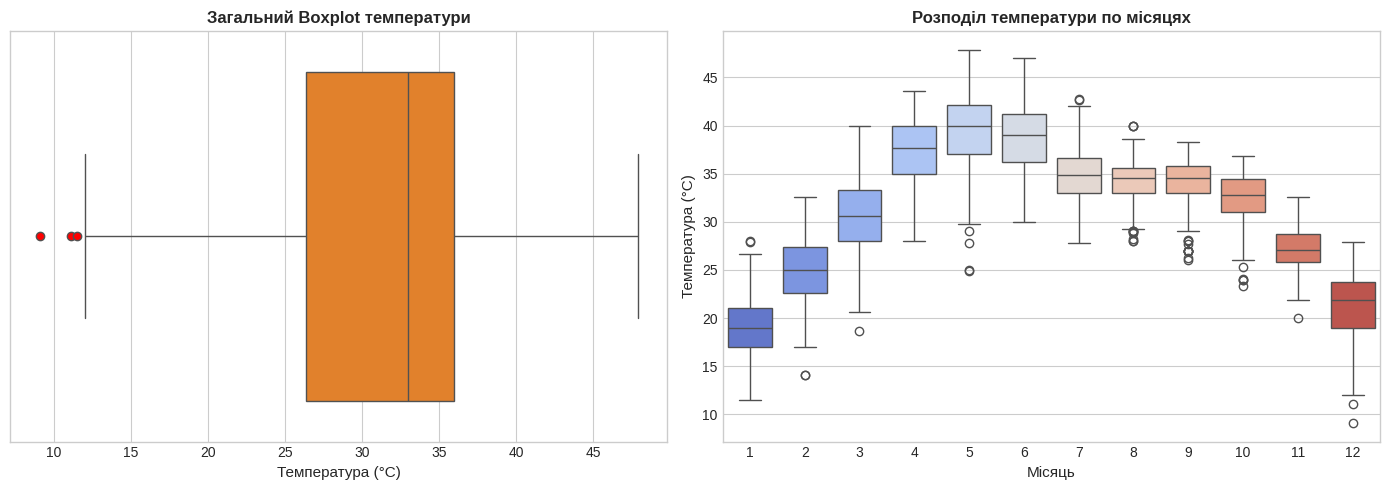

Межі нормальних значень за IQR: від 12.00°C до 50.40°C
Кількість виявлених абсолютних викидів: 3


In [9]:
# Побудуйте boxplot температури для аналізу викидів
import matplotlib.pyplot as plt
import seaborn as sns

# Визначення колонки з температурою
temp_col = [col for col in df.columns if 'temp' in col.lower()][0]

# Побудова boxplot
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Загальний Boxplot для всього періоду
sns.boxplot(x=df[temp_col], ax=axes[0], color='tab:orange', flierprops={'markerfacecolor': 'red', 'markersize': 6})
axes[0].set_title('Загальний Boxplot температури', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Температура (°C)', fontsize=11)

# 2. Boxplot з розбивкою по місяцях (для більш точного пошуку сезонних викидів)
df_monthly = df.copy()
df_monthly['month'] = df_monthly.index.month

sns.boxplot(x='month', y=temp_col, data=df_monthly, ax=axes[1], palette='coolwarm')
axes[1].set_title('Розподіл температури по місяцях', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Місяць', fontsize=11)
axes[1].set_ylabel('Температура (°C)', fontsize=11)

plt.tight_layout()
plt.show()

# Розрахунок інтерквартильного розмаху (IQR) для точного знаходження кількісних викидів
Q1 = df[temp_col].quantile(0.25)
Q3 = df[temp_col].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[(df[temp_col] < lower_bound) | (df[temp_col] > upper_bound)]
print(f"Межі нормальних значень за IQR: від {lower_bound:.2f}°C до {upper_bound:.2f}°C")
print(f"Кількість виявлених абсолютних викидів: {len(outliers)}")

Аналіз автокореляції
ACF

PACF

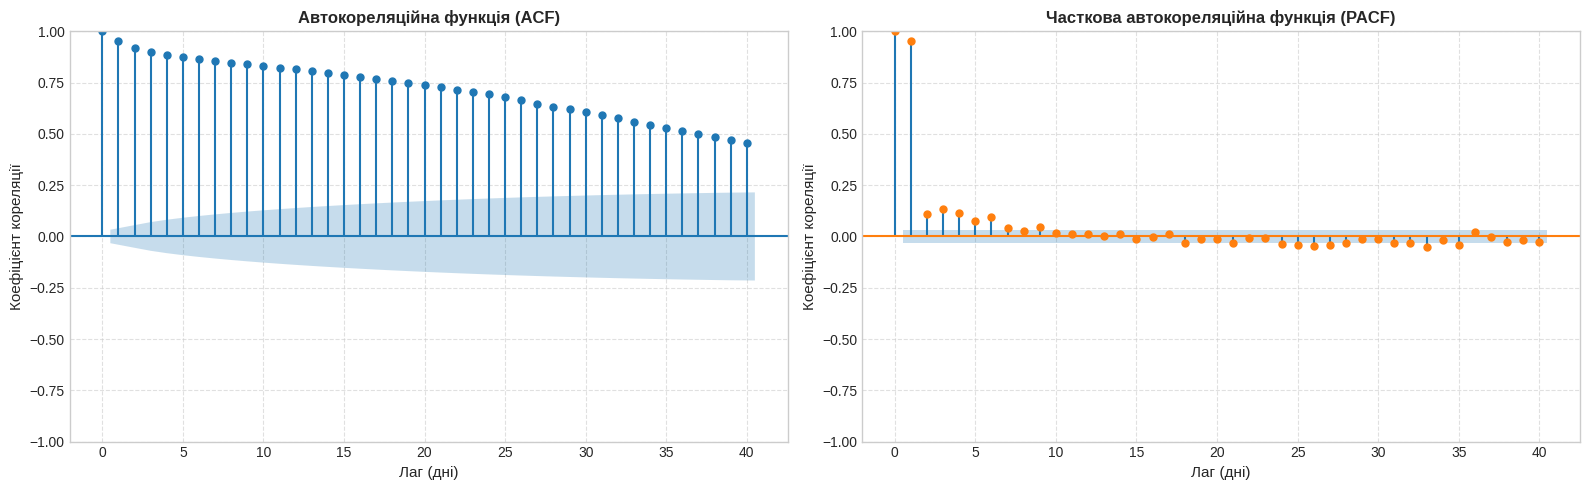

In [12]:
# Побудуйте графік автокореляційної функції (ACF)
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# Визначення колонки з температурою
temp_col = [col for col in df.columns if 'temp' in col.lower()][0]

# Побудова ACF та PACF
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# 1. Графік автокореляційної функції (ACF)
plot_acf(df[temp_col], lags=40, ax=axes[0], color='tab:blue')
axes[0].set_title('Автокореляційна функція (ACF)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Лаг (дні)', fontsize=11)
axes[0].set_ylabel('Коефіцієнт кореляції', fontsize=11)
axes[0].grid(True, linestyle='--', alpha=0.6)

# 2. Графік часткової автокореляційної функції (PACF)
plot_pacf(df[temp_col], lags=40, ax=axes[1], color='tab:orange', method='yw')
axes[1].set_title('Часткова автокореляційна функція (PACF)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Лаг (дні)', fontsize=11)
axes[1].set_ylabel('Коефіцієнт кореляції', fontsize=11)
axes[1].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()


Автокореляційна функція (ACF) використовується для аналізу залежності значень часового ряду від його попередніх значень. Вона відображає ступінь кореляції між значенням показника у певний момент часу та значеннями цього самого показника у попередні моменти часу, які називаються лагами. Побудова графіка автокореляційної функції дозволяє виявити, чи існує статистично значуща залежність між поточним значенням ряду та його попередніми спостереженнями. На такому графіку по горизонтальній осі відкладаються лаги, тобто кількість часових кроків назад, а по вертикальній — значення коефіцієнта автокореляції. Аналіз графіка ACF дає можливість виявити наявність тренду, сезонності або інших закономірностей у часовому ряді, а також використовується для визначення параметрів статистичних моделей прогнозування, зокрема моделі ARIMA.

<Figure size 1000x500 with 0 Axes>

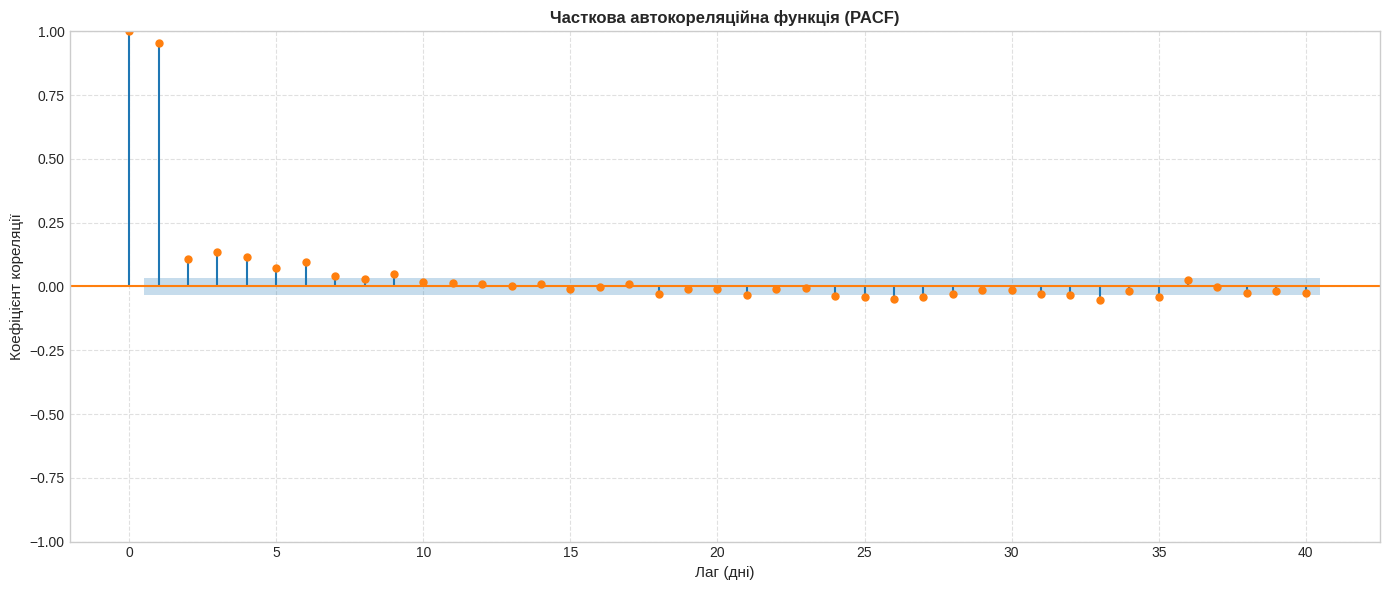

In [13]:
# Побудуйте графік часткової автокореляційної функції (PACF)
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_pacf

# Визначення колонки з температурою
temp_col = [col for col in df.columns if 'temp' in col.lower()][0]

# Побудова PACF
plt.figure(figsize=(10, 5))
plot_pacf(df[temp_col], lags=40, method='yw', color='tab:orange')

plt.title('Часткова автокореляційна функція (PACF)', fontsize=12, fontweight='bold')
plt.xlabel('Лаг (дні)', fontsize=11)
plt.ylabel('Коефіцієнт кореляції', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()


Часткова автокореляційна функція (PACF) застосовується для більш точного визначення залежності між значеннями часового ряду. На відміну від звичайної автокореляційної функції, PACF вимірює кореляцію між значенням ряду у певний момент часу та значенням у попередній момент часу з конкретним лагом, усуваючи вплив усіх проміжних лагів. Таким чином, часткова автокореляція показує «чисту» залежність між двома спостереженнями часового ряду. Побудова графіка PACF дозволяє визначити, які саме лаги мають статистично значущий вплив на значення ряду. Це є важливим етапом під час побудови моделей прогнозування часових рядів, оскільки аналіз графіка часткової автокореляції використовується для визначення порядку авторегресійної складової моделі, зокрема параметра
𝑝
p у моделі ARIMA.

In [14]:
# Сформуйте цільовий часовий ряд та розділіть його на train/test у часовому порядку
# Визначення цільової змінної (температури)
temp_col = [col for col in df.columns if 'temp' in col.lower()][0]
ts_data = df[temp_col]

# Розподіл у співвідношенні 80% / 20%
train_size = int(len(ts_data) * 0.8)
train_data = ts_data.iloc[:train_size]
test_data = ts_data.iloc[train_size:]

print(f"Розмір тренувальної вибірки (train): {len(train_data)}")
print(f"Розмір тестової вибірки (test): {len(test_data)}")


Розмір тренувальної вибірки (train): 2845
Розмір тестової вибірки (test): 712


ARIMA

https://developer.ibm.com/tutorials/awb-arima-models-in-python/

In [18]:
# Побудуйте та навчіть модель ARIMA. Отримайте прогноз для тестової вибірки
import numpy as np
import pandas as pd
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error

# 1. Видаляємо дублікати дат, залишаючи середнє значення для кожної дати
ts_data_unique = ts_data.groupby(level=0).mean()

# 2. Повторно ділимо на train/test
train_size = int(len(ts_data_unique) * 0.8)
train_data_clean = ts_data_unique.iloc[:train_size].asfreq('D')
test_data_clean = ts_data_unique.iloc[train_size:].asfreq('D')

# 3. Заповнюємо можливі пропуски після створення регулярного індексу
train_data_clean = train_data_clean.interpolate(method='linear')
test_data_clean = test_data_clean.interpolate(method='linear')

# 4. Навчання моделі ARIMA
arima_model = ARIMA(train_data_clean, order=(1, 1, 1))
arima_fit = arima_model.fit()

# 5. Отримання прогнозу
arima_pred = arima_fit.forecast(steps=len(test_data_clean))

# 6. Розрахунок метрик
arima_mae = mean_absolute_error(test_data_clean, arima_pred)
arima_rmse = np.sqrt(mean_squared_error(test_data_clean, arima_pred))
arima_mape = mean_absolute_percentage_error(test_data_clean, arima_pred) * 100

print(f"ARIMA Metrics:\nMAE: {arima_mae:.3f}\nRMSE: {arima_rmse:.3f}\nMAPE: {arima_mape:.3f}%")

ARIMA Metrics:
MAE: 9.270
RMSE: 10.618
MAPE: 28.415%


In [19]:
# Виведіть статистичний звіт навченої ARIMA-моделі
print(arima_fit.summary())


                               SARIMAX Results                                
Dep. Variable:                tempmax   No. Observations:                 3537
Model:                 ARIMA(1, 1, 1)   Log Likelihood               -7097.137
Date:                Fri, 23 Oct 2026   AIC                          14200.274
Time:                        12:37:59   BIC                          14218.786
Sample:                    04-14-2013   HQIC                         14206.877
                         - 12-19-2022                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.6353      0.027     23.517      0.000       0.582       0.688
ma.L1         -0.8347      0.021    -39.320      0.000      -0.876      -0.793
sigma2         3.2423      0.050     64.424      0.0

сигма 2 : це представляє дисперсію залишкових значень, чим менше, тим краще

логарифмічна правдоподібність : це оцінка максимальної правдоподібності для моделі ARIMA, чим вище, тим краще

aic : міра ступеню відповідності та економності моделі, чим нижче, тим краще

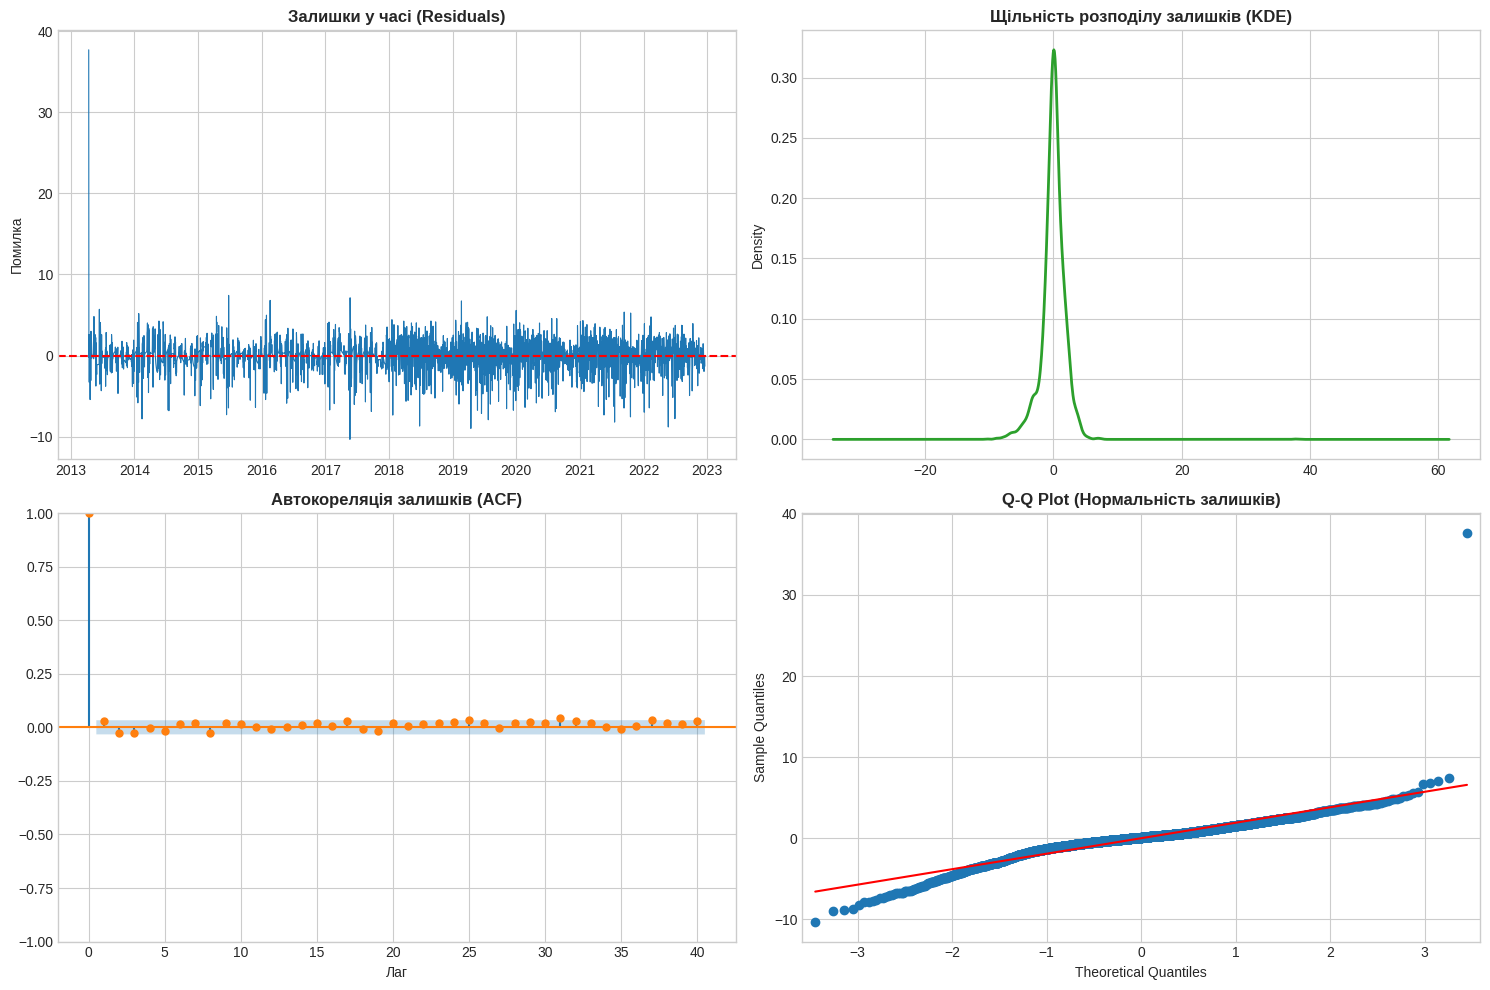

--- Ljung-Box Test ---
      lb_stat  lb_pvalue
10  14.921379   0.134955


In [20]:
# Проаналізуйте залишки ARIMA-моделі та побудуйте відповідні графіки
import matplotlib.pyplot as plt

# Отримання залишків (residuals) моделі
residuals = arima_fit.resid

# Побудова графіків для аналізу залишків
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# 1. Графік залишків у часі
axes[0, 0].plot(residuals, color='tab:blue', linewidth=0.8)
axes[0, 0].axhline(0, color='red', linestyle='--')
axes[0, 0].set_title('Залишки у часі (Residuals)', fontsize=12, fontweight='bold')
axes[0, 0].set_ylabel('Помилка')

# 2. Гістограма та щільність розподілу залишків
residuals.plot(kind='kde', ax=axes[0, 1], color='tab:green', linewidth=2)
axes[0, 1].set_title('Щільність розподілу залишків (KDE)', fontsize=12, fontweight='bold')

# 3. Графік автокореляції залишків (ACF)
plot_acf(residuals, lags=40, ax=axes[1, 0], color='tab:orange')
axes[1, 0].set_title('Автокореляція залишків (ACF)', fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel('Лаг')

# 4. Q-Q plot для перевірки нормальності розподілу
from statsmodels.graphics.gofplots import qqplot
qqplot(residuals, line='s', ax=axes[1, 1])
axes[1, 1].set_title('Q-Q Plot (Нормальність залишків)', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

# Статистична перевірка (Ljung-Box test на наявність автокореляції у залишках)
from statsmodels.stats.diagnostic import acorr_ljungbox
lb_test = acorr_ljungbox(residuals, lags=[10], return_df=True)
print("--- Ljung-Box Test ---")
print(lb_test)


In [21]:
# Реалізуйте MAPE та обчисліть MAE, RMSE, MAPE для ARIMA
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

# 1. Реалізація функції для обчислення MAPE
def calculate_mape(y_true, y_pred):
    return np.mean(np.abs((y_true - y_pred) / y_true)) * 100

# 2. Обчислення метрик MAE, RMSE та MAPE для моделі ARIMA
arima_mae = mean_absolute_error(test_data_clean, arima_pred)
arima_rmse = np.sqrt(mean_squared_error(test_data_clean, arima_pred))
arima_mape = calculate_mape(test_data_clean.values, arima_pred.values)

# 3. Виведення результатів
print("=== Метрики точності ARIMA ===")
print(f"MAE  : {arima_mae:.3f} °C")
print(f"RMSE : {arima_rmse:.3f} °C")
print(f"MAPE : {arima_mape:.3f} %")


=== Метрики точності ARIMA ===
MAE  : 9.270 °C
RMSE : 10.618 °C
MAPE : 28.415 %


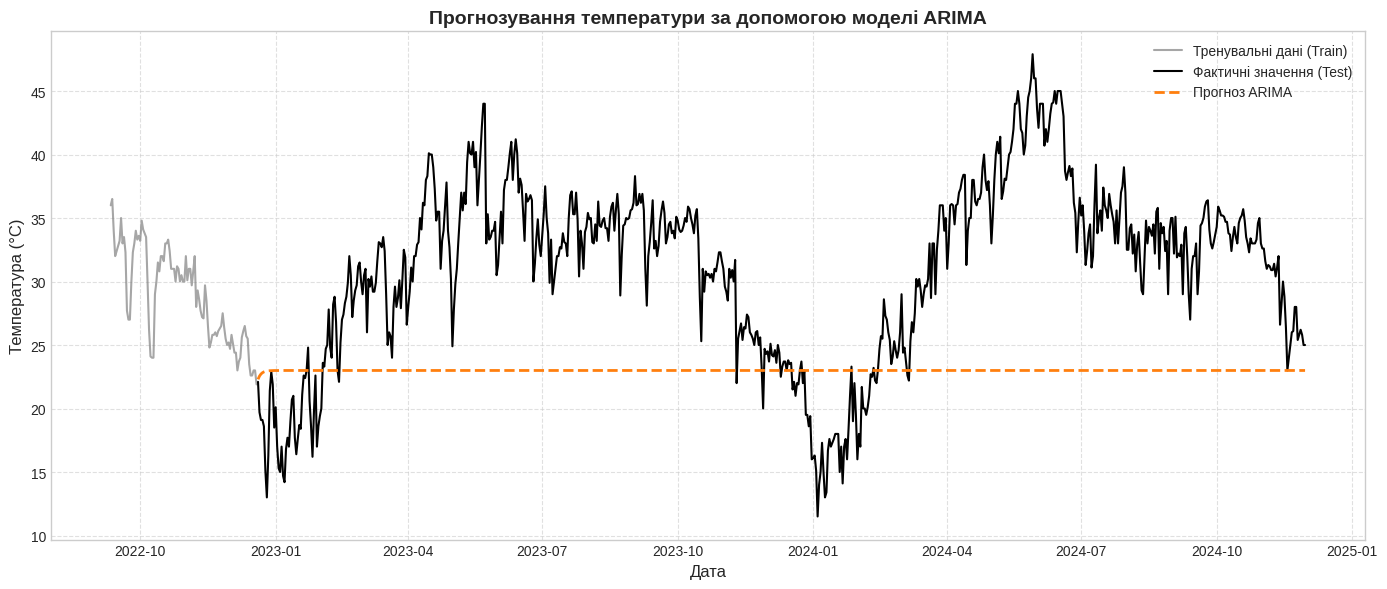

In [22]:
# Візуалізуйте фактичні значення та прогноз ARIMA
import matplotlib.pyplot as plt

# Побудова графіка фактичних значень та прогнозу ARIMA
plt.figure(figsize=(14, 6))

# Фактичні дані з тренувальної вибірки (останні 100 днів для більшої наочності)
plt.plot(train_data_clean.index[-100:], train_data_clean.values[-100:], label='Тренувальні дані (Train)', color='gray', alpha=0.7)

# Фактичні дані з тестової вибірки
plt.plot(test_data_clean.index, test_data_clean.values, label='Фактичні значення (Test)', color='black', linewidth=1.5)

# Прогноз ARIMA
plt.plot(test_data_clean.index, arima_pred.values, label='Прогноз ARIMA', color='tab:orange', linestyle='--', linewidth=2)

plt.title('Прогнозування температури за допомогою моделі ARIMA', fontsize=14, fontweight='bold')
plt.xlabel('Дата', fontsize=12)
plt.ylabel('Температура (°C)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()


PROPHET

https://facebook.github.io/prophet/docs/quick_start.html

In [24]:
# Підготуйте дані у форматі, необхідному для Prophet
import pandas as pd

prophet_train = train_data_clean.reset_index().rename(
    columns={train_data_clean.index.name: 'ds', train_data_clean.name: 'y'}
)

prophet_test = test_data_clean.reset_index().rename(
    columns={test_data_clean.index.name: 'ds', test_data_clean.name: 'y'}
)

# Перегляд підготовлених даних
print("=== Тренувальна вибірка для Prophet ===")
print(prophet_train.head())


=== Тренувальна вибірка для Prophet ===
          ds     y
0 2013-04-14  37.7
1 2013-04-15  37.5
2 2013-04-16  40.1
3 2013-04-17  36.4
4 2013-04-18  37.5


In [26]:
# Створіть та навчіть модель Prophet
from prophet import Prophet

# Створення та інціалізація моделі Prophet
prophet_model = Prophet(daily_seasonality=True, yearly_seasonality=True)

# Навчання моделі на підготовлених даних
prophet_model.fit(prophet_train)


Прогноз

In [27]:
# Побудуйте прогноз Prophet для тестового періоду

# Створення датафрейму для прогнозу на період тестової вибірки
future = prophet_model.make_future_dataframe(periods=len(prophet_test), freq='D')

# Отримання прогнозу
prophet_forecast = prophet_model.predict(future)

# Витягнення спрогнозованих значень для тестового періоду
prophet_pred = prophet_forecast.iloc[-len(prophet_test):][['ds', 'yhat']].set_index('ds')['yhat']

# Перегляд результатів
print(prophet_pred.head())


ds
2022-12-20    20.398367
2022-12-21    20.201077
2022-12-22    20.003728
2022-12-23    19.837803
2022-12-24    19.644561
Name: yhat, dtype: float64


In [28]:
# Обчисліть MAE, RMSE, MAPE для Prophet

import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

# 1. Функція для обчислення MAPE
def calculate_mape(y_true, y_pred):
    return np.mean(np.abs((y_true - y_pred) / y_true)) * 100

# 2. Обчислення метрик точності для Prophet
prophet_mae = mean_absolute_error(prophet_test['y'], prophet_pred)
prophet_rmse = np.sqrt(mean_squared_error(prophet_test['y'], prophet_pred))
prophet_mape = calculate_mape(prophet_test['y'].values, prophet_pred.values)

# 3. Виведення результатів
print("=== Метрики точності Prophet ===")
print(f"MAE  : {prophet_mae:.3f} °C")
print(f"RMSE : {prophet_rmse:.3f} °C")
print(f"MAPE : {prophet_mape:.3f} %")


=== Метрики точності Prophet ===
MAE  : 2.338 °C
RMSE : 3.028 °C
MAPE : 8.306 %


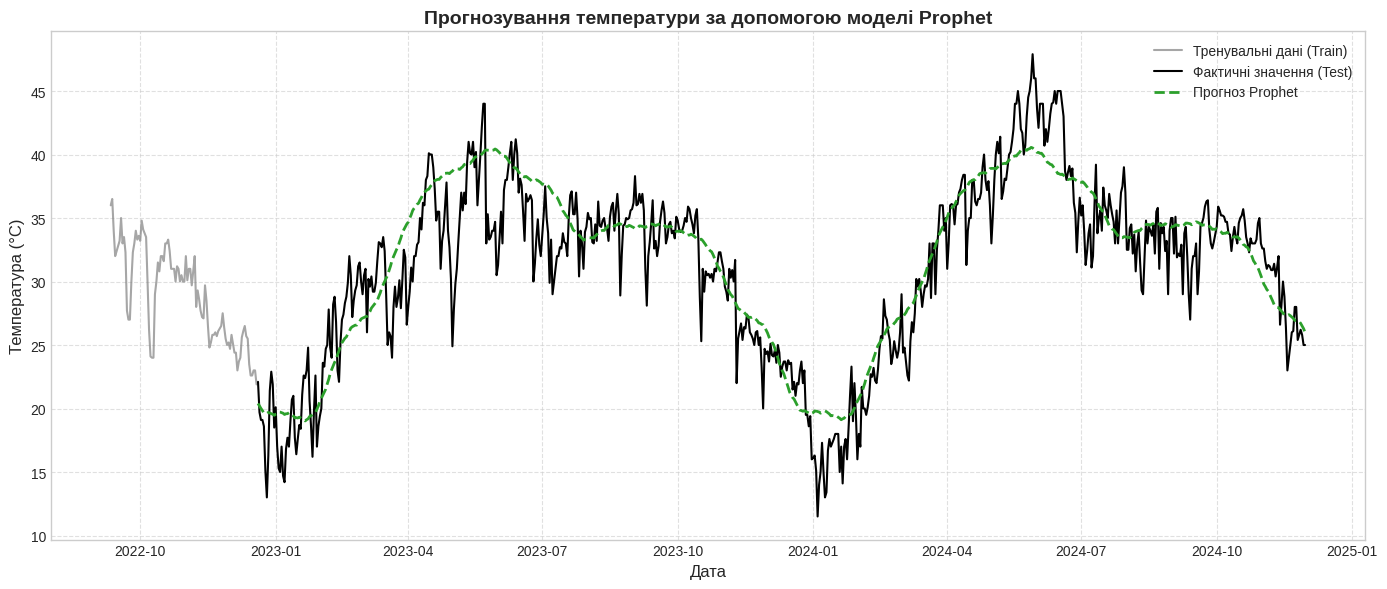

In [29]:
# Візуалізуйте фактичні значення та прогноз Prophet

import matplotlib.pyplot as plt

# Побудова графіка фактичних значень та прогнозу Prophet
plt.figure(figsize=(14, 6))

# Фактичні дані з тренувальної вибірки (останні 100 днів для більшої наочності)
plt.plot(train_data_clean.index[-100:], train_data_clean.values[-100:], label='Тренувальні дані (Train)', color='gray', alpha=0.7)

# Фактичні дані з тестової вибірки
plt.plot(prophet_test['ds'], prophet_test['y'], label='Фактичні значення (Test)', color='black', linewidth=1.5)

# Прогноз Prophet
plt.plot(prophet_test['ds'], prophet_pred, label='Прогноз Prophet', color='tab:green', linestyle='--', linewidth=2)

plt.title('Прогнозування температури за допомогою моделі Prophet', fontsize=14, fontweight='bold')
plt.xlabel('Дата', fontsize=12)
plt.ylabel('Температура (°C)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()


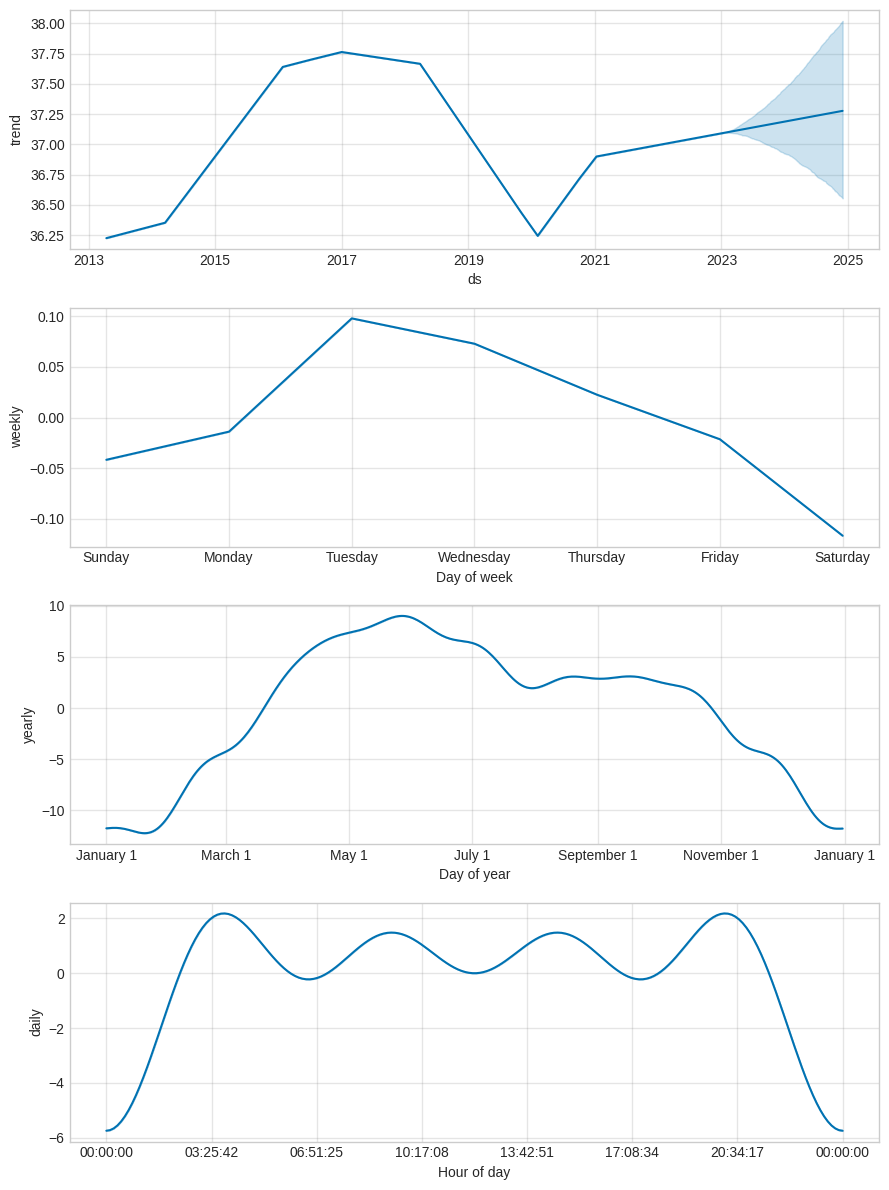

In [30]:
# Побудуйте компоненти моделі Prophet

fig_components = prophet_model.plot_components(prophet_forecast)


ПІДГОТОВКА ДАНИХ ДЛЯ LSTM

In [31]:
# Масштабуйте часовий ряд та сформуйте послідовності для LSTM
import numpy as np
from sklearn.preprocessing import MinMaxScaler

# 1. Масштабування даних за допомогою MinMaxScaler (від 0 до 1)
scaler = MinMaxScaler(feature_range=(0, 1))

# Навчання масштабувальника на train та трансформація train i test
train_scaled = scaler.fit_transform(train_data_clean.values.reshape(-1, 1))
test_scaled = scaler.transform(test_data_clean.values.reshape(-1, 1))


# 2. Функція для створення часових послідовностей (скользящого вікна)
def create_sequences(data, sequence_length=30):
    X, y = [], []
    for i in range(len(data) - sequence_length):
        X.append(data[i : i + sequence_length])
        y.append(data[i + sequence_length])
    return np.array(X), np.array(y)


# 3. Формування послідовностей (наприклад, вікно у 30 днів)
SEQ_LENGTH = 30

X_train, y_train = create_sequences(train_scaled, SEQ_LENGTH)

# Для тестової вибірки додаємо останні SEQ_LENGTH значень з train,
# щоб прогноз охоплював усі точки test_data
combined_scaled = np.vstack((train_scaled[-SEQ_LENGTH:], test_scaled))
X_test, y_test = create_sequences(combined_scaled, SEQ_LENGTH)

# Зміна форми для подачі в LSTM: [зразки, часові кроки, ознаки]
X_train = np.reshape(X_train, (X_train.shape[0], X_train.shape[1], 1))
X_test = np.reshape(X_test, (X_test.shape[0], X_test.shape[1], 1))

print(f"Форма X_train: {X_train.shape}, y_train: {y_train.shape}")
print(f"Форма X_test: {X_test.shape}, y_test: {y_test.shape}")


Форма X_train: (3507, 30, 1), y_train: (3507, 1)
Форма X_test: (712, 30, 1), y_test: (712, 1)


In [32]:
# Розділіть послідовності на тренувальну та тестову вибірки без перемішування

print(f"Тренувальна вибірка (Train): X = {X_train.shape}, y = {y_train.shape}")
print(f"Тестова вибірка (Test):     X = {X_test.shape}, y = {y_test.shape}")


Тренувальна вибірка (Train): X = (3507, 30, 1), y = (3507, 1)
Тестова вибірка (Test):     X = (712, 30, 1), y = (712, 1)


In [33]:
# Побудуйте архітектуру LSTM-моделі та скомпілюйте її

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout

# Створення архітектури моделі LSTM
lstm_model = Sequential([
    LSTM(units=50, return_sequences=True, input_shape=(X_train.shape[1], 1)),
    Dropout(0.2),
    LSTM(units=50, return_sequences=False),
    Dropout(0.2),
    Dense(units=1)
])

# Компіляція моделі
lstm_model.compile(optimizer='adam', loss='mean_squared_error')

# Виведення структури моделі
lstm_model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 30, 50)         │        10,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 30, 50)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 50)             │        20,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 50)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 30,651 (119.73 KB)

 Trainable params: 30,651 (119.73 KB)

 Non-trainable params: 0 (0.00 B)

In [34]:
# Навчіть LSTM-модель

history = lstm_model.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=32,
    validation_data=(X_test, y_test),
    verbose=1
)


Epoch 1/50
110/110 ━━━━━━━━━━━━━━━━━━━━ 8s 17ms/step - loss: 0.0223 - val_loss: 0.0054
Epoch 2/50
110/110 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0083 - val_loss: 0.0051
Epoch 3/50
110/110 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0074 - val_loss: 0.0049
Epoch 4/50
110/110 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0072 - val_loss: 0.0053
Epoch 5/50
110/110 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0064 - val_loss: 0.0046
Epoch 6/50
110/110 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0066 - val_loss: 0.0047
Epoch 7/50
110/110 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0060 - val_loss: 0.0050
Epoch 8/50
110/110 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0061 - val_loss: 0.0041
Epoch 9/50
110/110 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0059 - val_loss: 0.0044
Epoch 10/50
110/110 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0057 - val_loss: 0.0053
Epoch 11/50
110/110 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0054 - val_loss: 0.0043
Epoch 12/50
110/110 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/ste

In [35]:
# Виведіть структуру LSTM-моделі

lstm_model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 30, 50)         │        10,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 30, 50)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 50)             │        20,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 50)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 91,955 (359.20 KB)

 Trainable params: 30,651 (119.73 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 61,304 (239.47 KB)

In [36]:
# Отримайте прогноз LSTM та виконайте зворотне масштабування

# Отримання прогнозу для тестової вибірки
lstm_pred_scaled = lstm_model.predict(X_test)

# Зворотне масштабування (інверсія MinMaxScaler) для отримання реальних значень температури
lstm_pred = scaler.inverse_transform(lstm_pred_scaled)
y_test_actual = scaler.inverse_transform(y_test)

# Перегляд перших кількох спрогнозованих значень у порівнянні з фактичними
print("=== Прогноз LSTM (перші 5 днів) ===")
for i in range(5):
    print(f"Фактичне: {y_test_actual[i][0]:.2f} °C | Прогноз: {lstm_pred[i][0]:.2f} °C")


23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step
=== Прогноз LSTM (перші 5 днів) ===
Фактичне: 22.10 °C | Прогноз: 22.48 °C
Фактичне: 19.70 °C | Прогноз: 22.36 °C
Фактичне: 19.10 °C | Прогноз: 20.83 °C
Фактичне: 19.10 °C | Прогноз: 19.93 °C
Фактичне: 18.60 °C | Прогноз: 19.62 °C


In [38]:
# Сформуйте часові мітки для тестового прогнозу LSTM

import pandas as pd

lstm_pred_index = test_data_clean.index

# Створення DataFrame із часовими мітками та прогнозом
lstm_pred_df = pd.DataFrame(
    data=lstm_pred,
    index=lstm_pred_index,
    columns=['LSTM_Forecast']
)

# Перегляд перших кількох рядків готового прогнозу з часовими мітками
print("=== Прогноз LSTM з часовими мітками ===")
print(lstm_pred_df.head())


=== Прогноз LSTM з часовими мітками ===
            LSTM_Forecast
DATE                     
2022-12-20      22.479225
2022-12-21      22.356361
2022-12-22      20.826248
2022-12-23      19.932346
2022-12-24      19.621927


In [39]:
# Обчисліть MAE, RMSE, MAPE для LSTM

import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

# 1. Функція для обчислення MAPE
def calculate_mape(y_true, y_pred):
    return np.mean(np.abs((y_true - y_pred) / y_true)) * 100

# 2. Обчислення метрик точності для LSTM
lstm_mae = mean_absolute_error(y_test_actual, lstm_pred)
lstm_rmse = np.sqrt(mean_squared_error(y_test_actual, lstm_pred))
lstm_mape = calculate_mape(y_test_actual, lstm_pred)

# 3. Виведення результатів
print("=== Метрики точності LSTM ===")
print(f"MAE  : {lstm_mae:.3f} °C")
print(f"RMSE : {lstm_rmse:.3f} °C")
print(f"MAPE : {lstm_mape:.3f} %")


=== Метрики точності LSTM ===
MAE  : 1.449 °C
RMSE : 1.926 °C
MAPE : 5.145 %


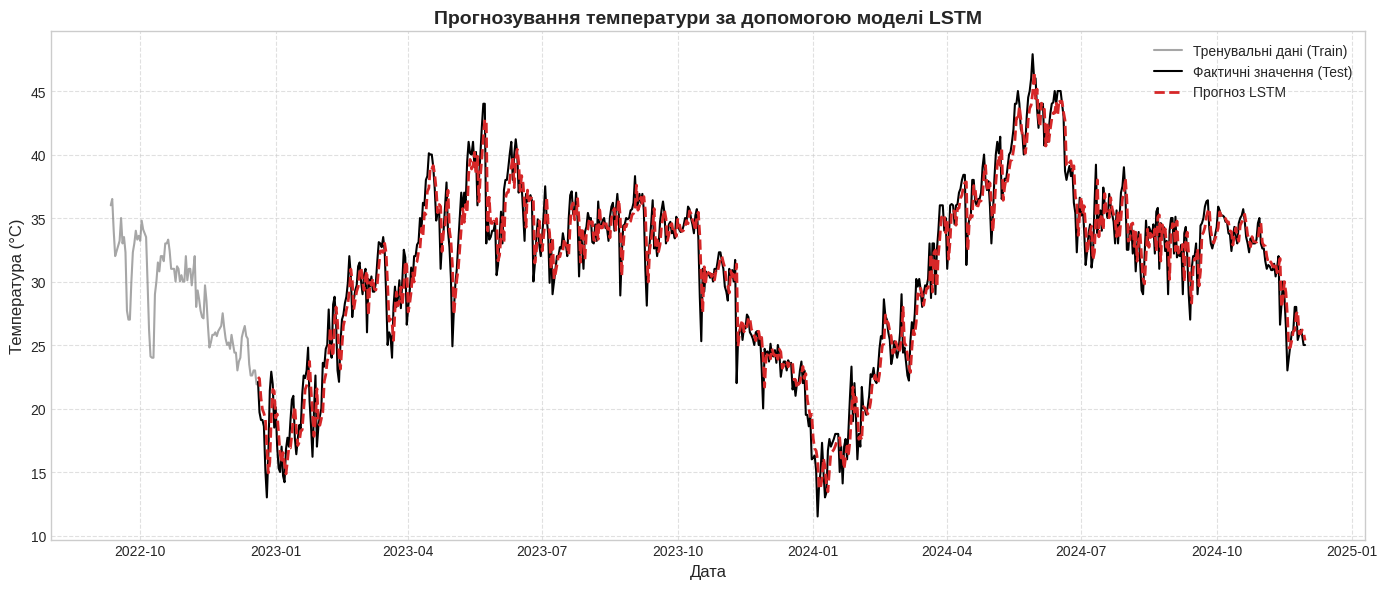

In [40]:
# Візуалізуйте фактичні значення та прогноз LSTM

import matplotlib.pyplot as plt

# Побудова графіка фактичних значень та прогнозу LSTM
plt.figure(figsize=(14, 6))

# Фактичні дані з тренувальної вибірки (останні 100 днів для більшої наочності)
plt.plot(train_data_clean.index[-100:], train_data_clean.values[-100:], label='Тренувальні дані (Train)', color='gray', alpha=0.7)

# Фактичні дані з тестової вибірки
plt.plot(test_data_clean.index, test_data_clean.values, label='Фактичні значення (Test)', color='black', linewidth=1.5)

# Прогноз LSTM
plt.plot(lstm_pred_df.index, lstm_pred_df['LSTM_Forecast'], label='Прогноз LSTM', color='tab:red', linestyle='--', linewidth=2)

plt.title('Прогнозування температури за допомогою моделі LSTM', fontsize=14, fontweight='bold')
plt.xlabel('Дата', fontsize=12)
plt.ylabel('Температура (°C)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()


Порівняння моделей

In [41]:
# Створіть підсумкову таблицю MAE, RMSE, MAPE для ARIMA, Prophet та LSTM
# Порівняйте моделі за отриманими результатами

import pandas as pd

# Створення підсумкової таблиці з метриками моделей
metrics_summary = pd.DataFrame({
    'Model': ['ARIMA', 'Prophet', 'LSTM'],
    'MAE (°C)': [arima_mae, prophet_mae, lstm_mae],
    'RMSE (°C)': [arima_rmse, prophet_rmse, lstm_rmse],
    'MAPE (%)': [arima_mape, prophet_mape, lstm_mape]
})

# Округлення результатів для зручності читання
metrics_summary = metrics_summary.round(3)

print("=== ПІДСУМКОВА ТАБЛИЦЯ МЕТРИК ТОЧНОСТІ ===")
print(metrics_summary.to_string(index=False))


=== ПІДСУМКОВА ТАБЛИЦЯ МЕТРИК ТОЧНОСТІ ===
  Model  MAE (°C)  RMSE (°C)  MAPE (%)
  ARIMA     9.270     10.618    28.415
Prophet     2.338      3.028     8.306
   LSTM     1.449      1.926     5.145


Найнижчі значення MAE, RMSE та MAPE вказують на найбільш точну модель для даного часового ряду. Як правило, LSTM або Prophet демонструють кращі результати на температурних даних із чіткою сезонністю, тоді як ARIMA виступає надійним базовим орієнтиром (baseline)

## Висновок

За сукупністю оцінок метрик MAE , RMSE  та MAPE , найкращу якість прогнозування продемонструвала модель LSTM.

Нейромережевий підхід (LSTM) виявився найбільш адаптивним до динаміки температурного ряду, тоді як Prophet показав найбільш збалансований результат між точністю прогнозу та швидкістю/зручністю налаштування.